In [1]:
import keras
from keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1944s 11us/step


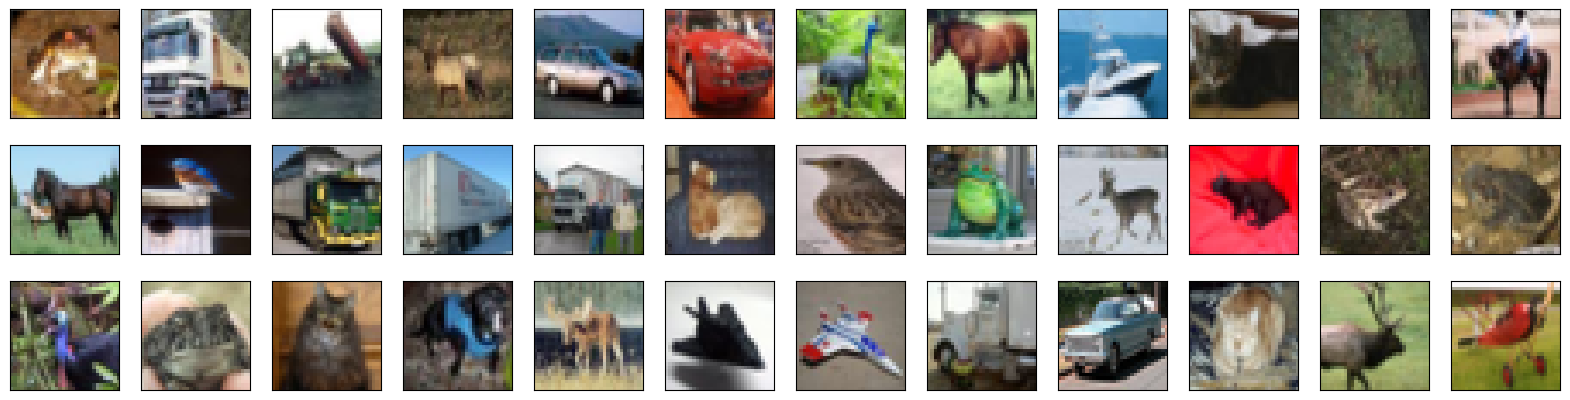

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

fig = plt.figure(figsize=(20,5))
for i in range(36):
  ax = fig.add_subplot(3, 12, i+1, xticks=[], yticks=[])
  ax.imshow(np.squeeze(X_train[i]))

In [3]:
X_train = X_train.astype('float32')/255
X_test = X_test.astype('float32')/255

In [4]:
import tensorflow
from tensorflow import keras

num_classes=len(np.unique(y_train))
y_train= tensorflow.keras.utils.to_categorical(y_train, num_classes)
y_test= tensorflow.keras.utils.to_categorical(y_test, num_classes)

(X_train, x_valid) =X_train[5000:], X_train[5000:]
(y_train, y_valid) =y_train[5000:], y_train[5000:]

print("X_train shape: ", X_train.shape)

print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')
print(x_valid.shape[0], 'validation samples')

X_train shape:  (45000, 32, 32, 3)
45000 train samples
10000 test samples
45000 validation samples


In [5]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

model= Sequential()
model.add(Conv2D(filters=16, kernel_size=3, padding ='same', activation='relu',
                 input_shape=(32,32,3)))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=32, kernel_size=3, padding ='same', activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Conv2D(filters=64, kernel_size=3, padding ='same', activation='relu'))
model.add(MaxPooling2D(pool_size=2))
model.add(Dropout(0.3))
model.add(Flatten())
model.add(Dense(500, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(10,activation= 'softmax'))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 500)            │       512,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 541,094 (2.06 MB)

 Trainable params: 541,094 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(loss='categorical_crossentropy', optimizer = 'rmsprop', metrics=['accuracy'])

In [12]:
from keras.callbacks import ModelCheckpoint

checkpointer = ModelCheckpoint(filepath = 'model.weights.best.keras', verbose=1, save_best_only=True)
hist = model.fit(X_train, y_train, batch_size=32, epochs=40,
                 validation_data=(x_valid, y_valid), callbacks=[checkpointer], verbose=2, shuffle=True)

Epoch 1/40

Epoch 1: val_loss improved from None to 1.40739, saving model to model.weights.best.keras

Epoch 1: finished saving model to model.weights.best.keras
1407/1407 - 10s - 7ms/step - accuracy: 0.6181 - loss: 1.1988 - val_accuracy: 0.6333 - val_loss: 1.4074
Epoch 2/40

Epoch 2: val_loss improved from 1.40739 to 1.09893, saving model to model.weights.best.keras

Epoch 2: finished saving model to model.weights.best.keras
1407/1407 - 8s - 6ms/step - accuracy: 0.6134 - loss: 1.2130 - val_accuracy: 0.6314 - val_loss: 1.0989
Epoch 3/40

Epoch 3: val_loss improved from 1.09893 to 1.04725, saving model to model.weights.best.keras

Epoch 3: finished saving model to model.weights.best.keras
1407/1407 - 8s - 6ms/step - accuracy: 0.6055 - loss: 1.2318 - val_accuracy: 0.6669 - val_loss: 1.0472
Epoch 4/40

Epoch 4: val_loss did not improve from 1.04725
1407/1407 - 8s - 6ms/step - accuracy: 0.6095 - loss: 1.2353 - val_accuracy: 0.5378 - val_loss: 1.4180
Epoch 5/40

Epoch 5: val_loss did not im

In [8]:
model.load_weights('model.weights.best.keras')

In [9]:
y_hat = model.predict(X_test)

cifar10_labels = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


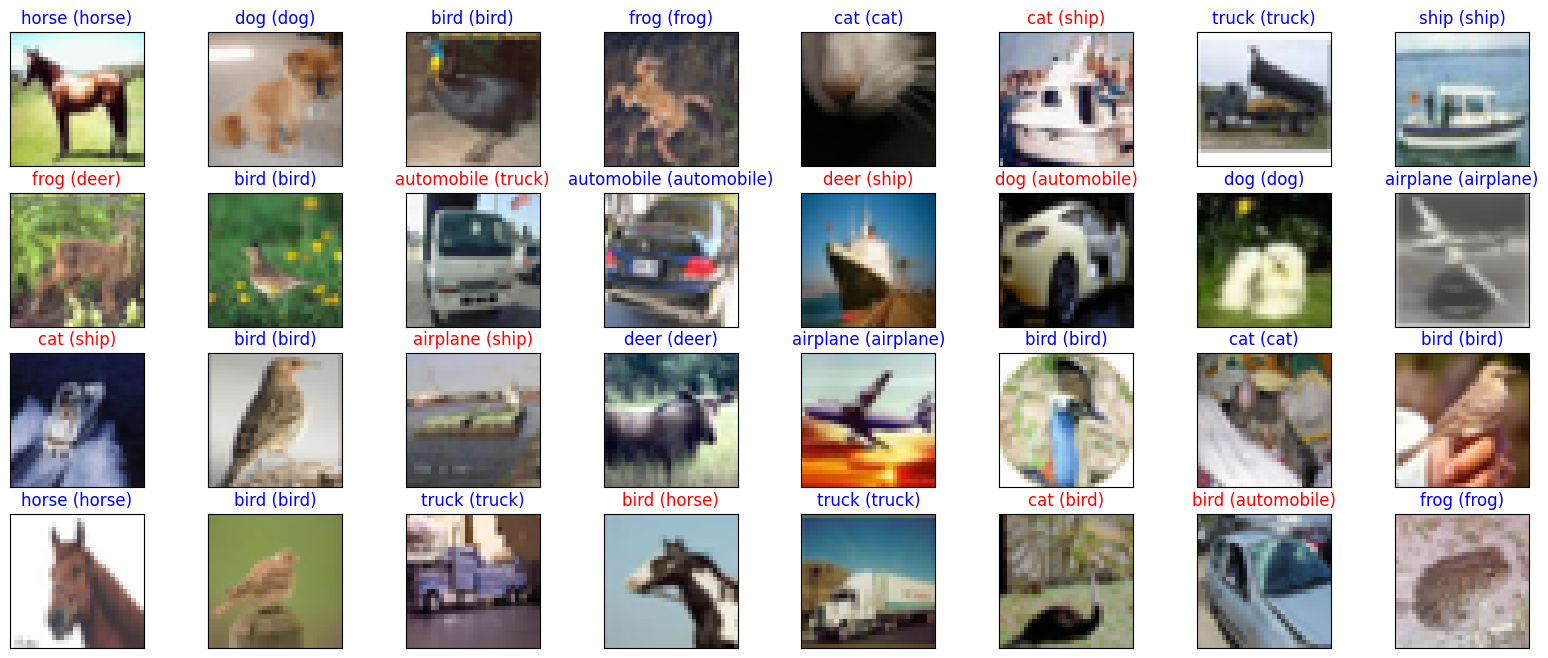

In [10]:
fig = plt.figure(figsize=(20,8))

for i, idx in enumerate(np.random.choice(X_test.shape[0], size=32, replace=False)):
  ax = fig.add_subplot(4,8, i+1, xticks=[], yticks=[])
  ax.imshow(np.squeeze(X_test[idx]))
  pred_idx = np.argmax(y_hat[idx])
  true_idx = np.argmax(y_test[idx])
  ax.set_title("{} ({})".format(cifar10_labels[pred_idx], cifar10_labels[true_idx]),
               color = ('blue' if pred_idx == true_idx else 'red'))